In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
DATA_DIR = Path(r"C:\Users\DELL\Downloads\OSMetrics")

### Load the CPU dataset

In [4]:
cpu = pd.read_csv(DATA_DIR / "cpu_usage.csv")
print(cpu.head())

                  Time  Value
0  2025-12-11 01:00:00      2
1  2025-12-11 01:00:15      1
2  2025-12-11 01:00:30      2
3  2025-12-11 01:00:45      1
4  2025-12-11 01:01:00      2


### Understand the dataset

In [5]:
print("Dataset shape:", cpu.shape)
print("\nColumn names:")
print(cpu.columns)

print("\nData types:")
print(cpu.dtypes)

print("\nStatistical summary:")
print(cpu["Value"].describe())

Dataset shape: (40320, 2)

Column names:
Index(['Time', 'Value'], dtype='str')

Data types:
Time       str
Value    int64
dtype: object

Statistical summary:
count    40320.000000
mean         3.538765
std          7.269774
min          0.000000
25%          1.000000
50%          2.000000
75%          2.000000
max         87.000000
Name: Value, dtype: float64


#### Load each monitoring file

In [6]:
cpu = pd.read_csv(DATA_DIR / "cpu_usage.csv")
memory = pd.read_csv(DATA_DIR / "memory_usage.csv")
memory_used = pd.read_csv(DATA_DIR / "memory_used.csv")

response_a = pd.read_csv(DATA_DIR / "network_response_time_a.csv")

response_b = pd.read_csv(DATA_DIR / "network_response_time_b.csv")

#### Rename Value to meaningful column names

In [8]:
cpu = cpu.rename(columns={"Value": "CPU"})
memory = memory.rename(columns={"Value": "Memory"})
memory_used = memory_used.rename(columns={"Value": "Memory_Used"})
response_a = response_a.rename(columns={"Value": "Response_Time_A"})
response_b = response_b.rename(columns={"Value": "Response_Time_B"})

#### Merge measurements using their timestamp

In [9]:
df = cpu.merge(memory, on="Time", how="outer")
df = df.merge(memory_used, on="Time", how="outer")
df = df.merge(response_a, on="Time", how="outer")
df = df.merge(response_b, on="Time", how="outer")

print(df.head())
print("\nCombined shape:", df.shape)

                  Time  CPU  Memory  Memory_Used  Response_Time_A  \
0  2025-12-11 01:00:00    2    18.1         1394              185   
1  2025-12-11 01:00:15    1    18.2         1400              184   
2  2025-12-11 01:00:30    2    18.1         1392              184   
3  2025-12-11 01:00:45    1    18.0         1381              184   
4  2025-12-11 01:01:00    2    18.0         1384              185   

   Response_Time_B  
0              560  
1              495  
2              541  
3              615  
4              583  

Combined shape: (40320, 6)


### Cleaning the dataset

In [10]:
df = df.copy()

# Convert timestamps to datetime format
df["Time"] = pd.to_datetime(df["Time"], errors="coerce")

# Convert measurement columns to numeric
features = [
    "CPU",
    "Memory",
    "Memory_Used",
    "Response_Time_A",
    "Response_Time_B"
]

for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [11]:
# Replace the known invalid response-time marker
response_cols = ["Response_Time_A", "Response_Time_B"]

df[response_cols] = df[response_cols].replace(-99999, np.nan)

# Replace infinite values with missing values
df[features] = df[features].replace(
    [np.inf, -np.inf], np.nan
)

In [12]:
# Remove records with invalid timestamps
df = df.dropna(subset=["Time"])

# Remove duplicate timestamps
df = df.drop_duplicates(subset=["Time"])

# Sort by time
df = df.sort_values("Time").reset_index(drop=True)

print("Missing values before handling:")
print(df[features].isnull().sum())


Missing values before handling:
CPU                 0
Memory              0
Memory_Used         0
Response_Time_A     1
Response_Time_B    12
dtype: int64


In [13]:
# Fill missing measurement values using time interpolation
df = df.set_index("Time")
df[features] = df[features].interpolate(
    method="time",
    limit_area="inside"
)

# Remove rows that still contain missing features
df = df.dropna(subset=features)

In [14]:
# Check for negative values in these non-negative metrics
nonnegative_cols = features

for col in nonnegative_cols:
    df.loc[df[col] < 0, col] = np.nan


In [15]:
# Remove remaining invalid rows
df = df.dropna(subset=features)

df = df.reset_index()

print("\nCleaned dataset shape:", df.shape)
print("\nRemaining missing values:")
print(df[features].isnull().sum())
print("\nCleaned data:")
print(df.head())


Cleaned dataset shape: (40320, 6)

Remaining missing values:
CPU                0
Memory             0
Memory_Used        0
Response_Time_A    0
Response_Time_B    0
dtype: int64

Cleaned data:
                 Time  CPU  Memory  Memory_Used  Response_Time_A  \
0 2025-12-11 01:00:00  2.0    18.1       1394.0            185.0   
1 2025-12-11 01:00:15  1.0    18.2       1400.0            184.0   
2 2025-12-11 01:00:30  2.0    18.1       1392.0            184.0   
3 2025-12-11 01:00:45  1.0    18.0       1381.0            184.0   
4 2025-12-11 01:01:00  2.0    18.0       1384.0            185.0   

   Response_Time_B  
0            560.0  
1            495.0  
2            541.0  
3            615.0  
4            583.0  


#### Exploratory data analysis (EDA)

In [16]:
#Check summary statistics
print(df[features].describe().round(2))

            CPU    Memory  Memory_Used  Response_Time_A  Response_Time_B
count  40320.00  40320.00     40320.00         40320.00         40320.00
mean       3.54     20.04      1540.20           279.45           696.39
std        7.27      8.20       629.88           495.79           546.47
min        0.00     17.60      1350.00            92.00           240.00
25%        1.00     18.10      1388.00           184.00           528.00
50%        2.00     18.20      1399.00           185.00           555.00
75%        2.00     18.40      1412.00           185.00           589.00
max       87.00     85.50      6568.00          7731.00          9337.00


#### Plot CPU usage

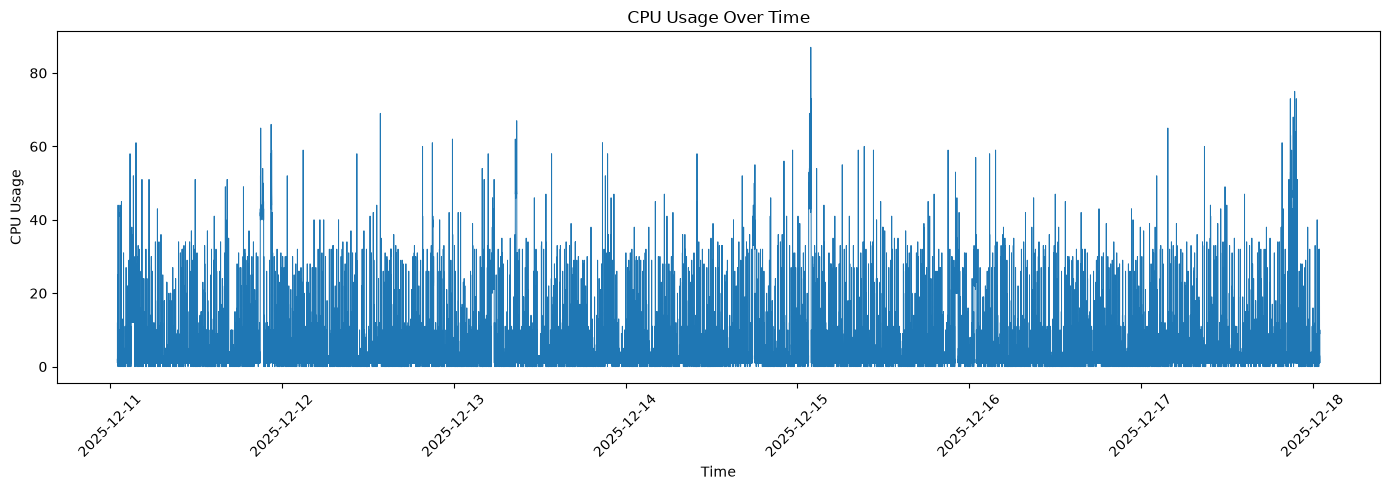

In [17]:
plt.figure(figsize=(14, 5))

plt.plot(df["Time"], df["CPU"], linewidth=0.7)

plt.title("CPU Usage Over Time")
plt.xlabel("Time")
plt.ylabel("CPU Usage")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Plot memory usage

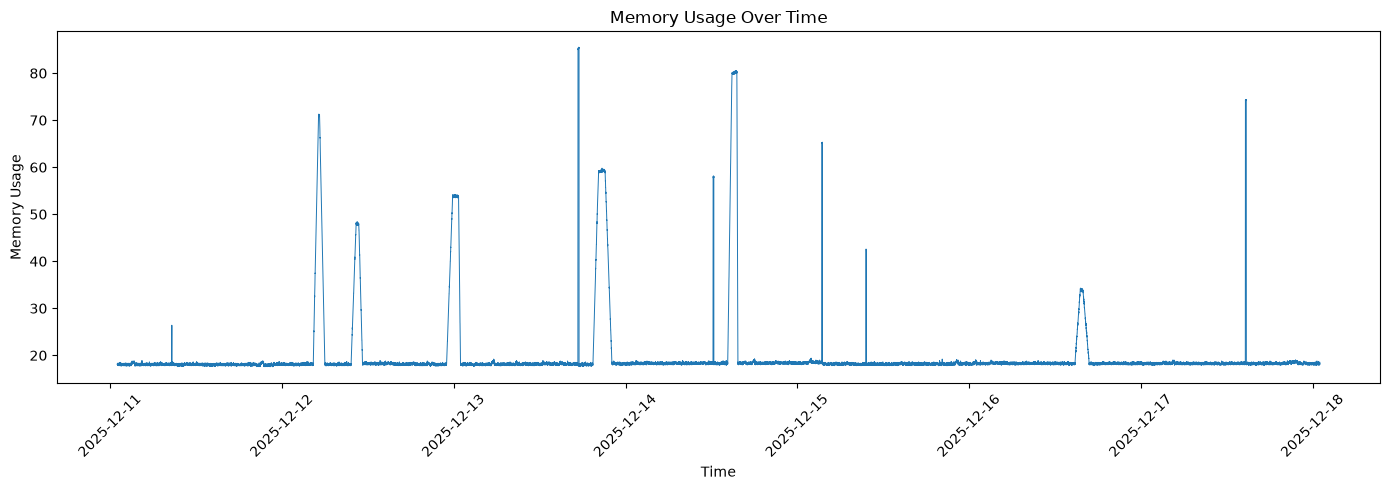

In [18]:
plt.figure(figsize=(14, 5))

plt.plot(df["Time"], df["Memory"], linewidth=0.7)

plt.title("Memory Usage Over Time")
plt.xlabel("Time")
plt.ylabel("Memory Usage")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Plot response time

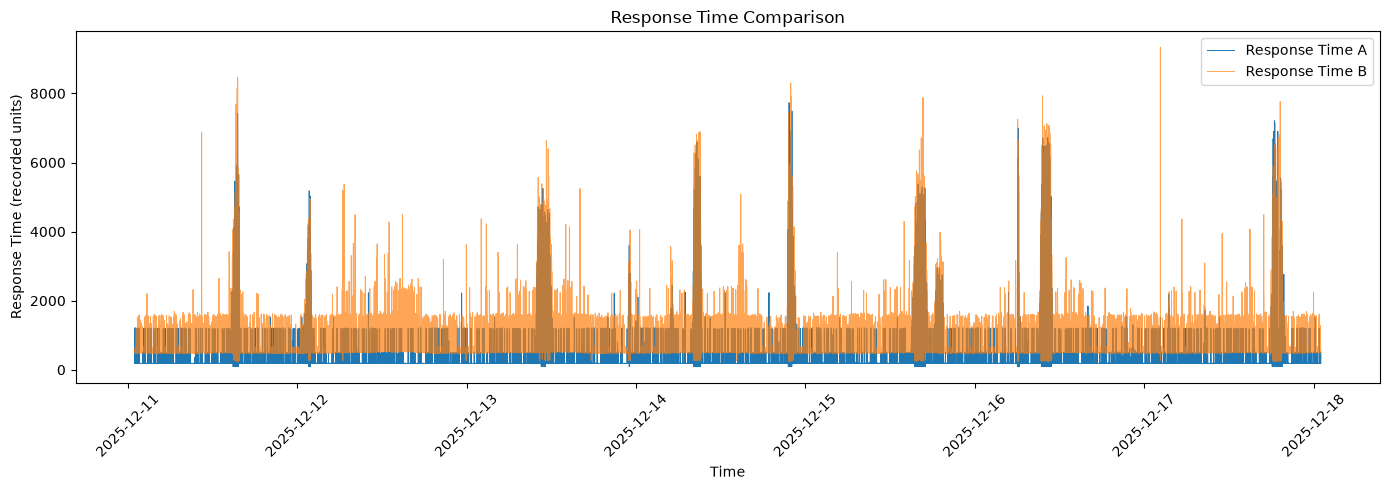

In [19]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["Time"],
    df["Response_Time_A"],
    label="Response Time A",
    linewidth=0.7
)

plt.plot(
    df["Time"],
    df["Response_Time_B"],
    label="Response Time B",
    linewidth=0.7,
    alpha=0.7
)

plt.title("Response Time Comparison")
plt.xlabel("Time")
plt.ylabel("Response Time (recorded units)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### View correlations

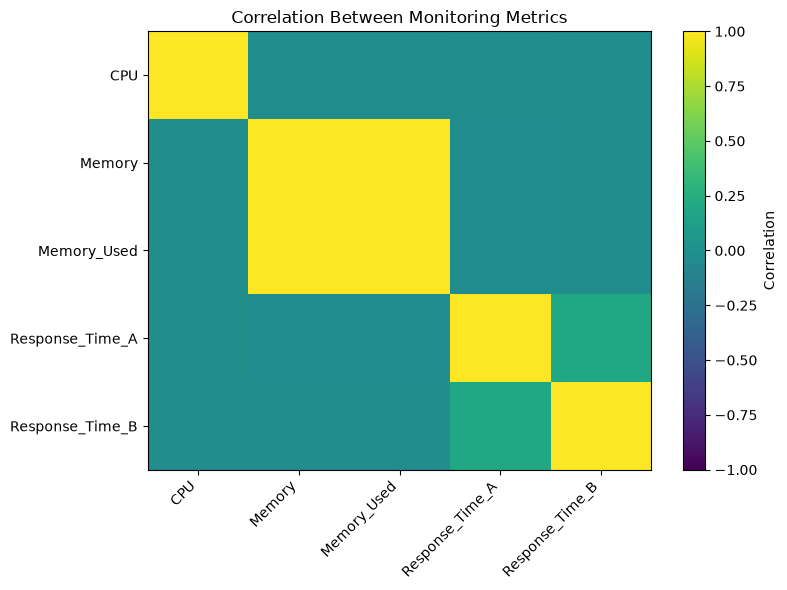

In [20]:
correlation = df[features].corr()

plt.figure(figsize=(8, 6))

plt.imshow(correlation, aspect="auto", vmin=-1, vmax=1)

plt.xticks(
    range(len(features)),
    features,
    rotation=45,
    ha="right"
)

plt.yticks(range(len(features)), features)

plt.colorbar(label="Correlation")
plt.title("Correlation Between Monitoring Metrics")
plt.tight_layout()
plt.show()

#### Prepare the features for machine learning

In [21]:
# Add time-related features
df["Hour"] = df["Time"].dt.hour
df["DayOfWeek"] = df["Time"].dt.dayofweek

model_features = [
    "CPU",
    "Memory",
    "Memory_Used",
    "Response_Time_A",
    "Response_Time_B",
    "Hour",
    "DayOfWeek"
]

X = df[model_features].copy()

print("Model features:", model_features)
print("\nFeature matrix shape:", X.shape)
print(X.head())

Model features: ['CPU', 'Memory', 'Memory_Used', 'Response_Time_A', 'Response_Time_B', 'Hour', 'DayOfWeek']

Feature matrix shape: (40320, 7)
   CPU  Memory  Memory_Used  Response_Time_A  Response_Time_B  Hour  DayOfWeek
0  2.0    18.1       1394.0            185.0            560.0     1          3
1  1.0    18.2       1400.0            184.0            495.0     1          3
2  2.0    18.1       1392.0            184.0            541.0     1          3
3  1.0    18.0       1381.0            184.0            615.0     1          3
4  2.0    18.0       1384.0            185.0            583.0     1          3


#### Isolation Forest is an unsupervised machine-learning algorithm. It tries to identify observations that can be isolated more easily than typical observations.

In [22]:
from sklearn.ensemble import IsolationForest

# Create the model
model = IsolationForest(
    n_estimators=100,
    contamination=0.02,
    random_state=42
)

# Train the model and predict anomalies
predictions = model.fit_predict(X)

# Add results to the dataset
df["Prediction"] = predictions

# Convert model output to readable labels
df["Anomaly"] = df["Prediction"].map({1: "Normal",-1: "Anomaly"})

# Obtain anomaly scores
df["Anomaly_Score"] = model.decision_function(X)

print(df[["Time","CPU","Memory","Response_Time_A","Response_Time_B","Anomaly","Anomaly_Score"]].head(20))

                  Time   CPU  Memory  Response_Time_A  Response_Time_B  \
0  2025-12-11 01:00:00   2.0    18.1            185.0            560.0   
1  2025-12-11 01:00:15   1.0    18.2            184.0            495.0   
2  2025-12-11 01:00:30   2.0    18.1            184.0            541.0   
3  2025-12-11 01:00:45   1.0    18.0            184.0            615.0   
4  2025-12-11 01:01:00   2.0    18.0            185.0            583.0   
5  2025-12-11 01:01:15  12.0    18.2            185.0            569.0   
6  2025-12-11 01:01:30   3.0    18.3            185.0            624.0   
7  2025-12-11 01:01:45   3.0    18.0            508.0            543.0   
8  2025-12-11 01:02:00   1.0    18.0           1217.0            505.0   
9  2025-12-11 01:02:15   1.0    18.0            185.0            606.0   
10 2025-12-11 01:02:30  14.0    17.9            184.0            554.0   
11 2025-12-11 01:02:45   1.0    17.9            184.0            548.0   
12 2025-12-11 01:03:00   2.0    18.0  

#### Identify and display anomalies

In [23]:
# Extract only anomalous observations
anomalies = df[df["Anomaly"] == "Anomaly"].copy()

print("Total observations:", len(df))
print("Anomalies detected:", len(anomalies))

print("\nAnomaly percentage:")
print(round(len(anomalies) / len(df) * 100, 2), "%")

print("\nFirst 20 anomalies:")

print(anomalies[["Time","CPU","Memory","Memory_Used","Response_Time_A","Response_Time_B","Anomaly_Score"]].head(20))

Total observations: 40320
Anomalies detected: 806

Anomaly percentage:
2.0 %

First 20 anomalies:
                    Time   CPU  Memory  Memory_Used  Response_Time_A  \
427  2025-12-11 02:46:45  58.0    18.3       1406.0           1208.0   
3396 2025-12-11 15:09:00  15.0    18.3       1410.0           3715.0   
3402 2025-12-11 15:10:30   3.0    18.0       1387.0           2138.0   
3403 2025-12-11 15:10:45   2.0    18.0       1387.0           4846.0   
3412 2025-12-11 15:13:00   2.0    18.3       1403.0           1673.0   
3477 2025-12-11 15:29:15   1.0    18.0       1386.0           1714.0   
3492 2025-12-11 15:33:00   1.0    18.0       1380.0           7423.0   
3493 2025-12-11 15:33:15   2.0    18.0       1381.0           2517.0   
3523 2025-12-11 15:40:45  24.0    17.9       1376.0           3792.0   
3529 2025-12-11 15:42:15   1.0    18.1       1392.0           5656.0   
3534 2025-12-11 15:43:30   2.0    17.8       1370.0           4711.0   
5152 2025-12-11 22:28:00  46.0    17.9

#### Visualize the detected anomalies

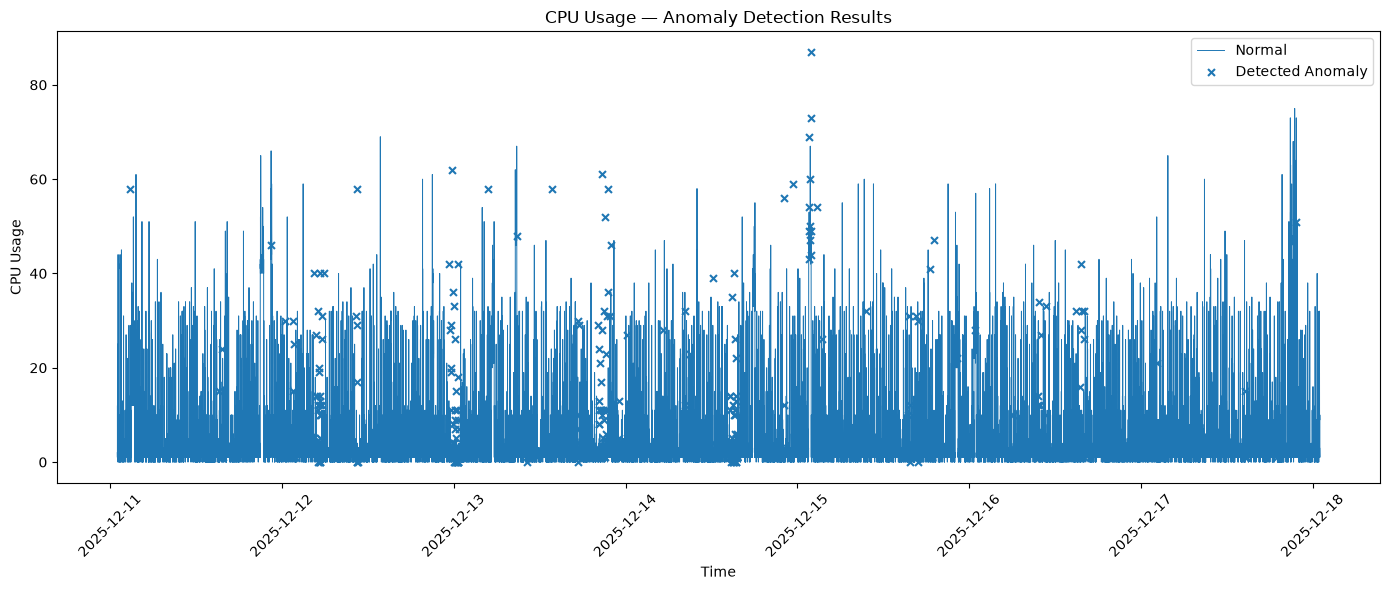

In [24]:
normal_data = df[df["Anomaly"] == "Normal"]
anomaly_data = df[df["Anomaly"] == "Anomaly"]

plt.figure(figsize=(14, 6))

plt.plot(normal_data["Time"],normal_data["CPU"],label="Normal",linewidth=0.7)

plt.scatter(anomaly_data["Time"],anomaly_data["CPU"],label="Detected Anomaly",marker="x",s=25)

plt.title("CPU Usage — Anomaly Detection Results")
plt.xlabel("Time")
plt.ylabel("CPU Usage")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Create the alert system

In [25]:
def generate_alert(row):
    reasons = []

    # Example threshold rules; tune to your system
    if row["CPU"] > 80:
        reasons.append("High CPU usage")

    if row["Memory"] > 80:
        reasons.append("High memory usage")

    if row["Response_Time_A"] > 1000:
        reasons.append("High response time A")

    if row["Response_Time_B"] > 1000:
        reasons.append("High response time B")

    if not reasons:
        reasons.append("Unusual combination of metrics")

    return ", ".join(reasons)


# Keep only anomalies and add alert descriptions
alerts = anomalies.copy()

alerts["Alert_Reason"] = alerts.apply(
    generate_alert,
    axis=1
)

alerts["Alert_Status"] = "ANOMALY DETECTED"

# Show the latest 10 alerts
print(alerts[["Time","CPU","Memory","Response_Time_A","Response_Time_B","Alert_Reason","Alert_Status"]].tail(10).to_string(index=False))

               Time  CPU  Memory  Response_Time_A  Response_Time_B                               Alert_Reason     Alert_Status
2025-12-17 14:41:45  3.0    74.4            185.0            514.0             Unusual combination of metrics ANOMALY DETECTED
2025-12-17 14:42:00  2.0    74.3            185.0            626.0             Unusual combination of metrics ANOMALY DETECTED
2025-12-17 14:42:15  3.0    74.4            185.0            563.0             Unusual combination of metrics ANOMALY DETECTED
2025-12-17 14:42:30  3.0    74.2            185.0            591.0             Unusual combination of metrics ANOMALY DETECTED
2025-12-17 14:42:45  4.0    74.3            185.0            561.0             Unusual combination of metrics ANOMALY DETECTED
2025-12-17 18:33:45  2.0    18.2           1192.0           6019.0 High response time A, High response time B ANOMALY DETECTED
2025-12-17 18:36:45  3.0    18.4           4886.0           3631.0 High response time A, High response time B A

#### Add severity levels

In [26]:
def get_severity(row):
    if (
        row["CPU"] > 90
        or row["Memory"] > 90
        or row["Response_Time_A"] > 3000
        or row["Response_Time_B"] > 3000
    ):
        return "Critical"

    if (
        row["CPU"] > 80
        or row["Memory"] > 80
        or row["Response_Time_A"] > 1000
        or row["Response_Time_B"] > 1000
    ):
        return "High"

    return "Review"

alerts["Severity"] = alerts.apply(
    get_severity,
    axis=1
)

print(alerts[["Time","Severity","Alert_Reason","Alert_Status"]].tail(10))

                     Time  Severity  \
37847 2025-12-17 14:41:45    Review   
37848 2025-12-17 14:42:00    Review   
37849 2025-12-17 14:42:15    Review   
37850 2025-12-17 14:42:30    Review   
37851 2025-12-17 14:42:45    Review   
38775 2025-12-17 18:33:45  Critical   
38787 2025-12-17 18:36:45  Critical   
38812 2025-12-17 18:43:00  Critical   
38874 2025-12-17 18:58:30  Critical   
39534 2025-12-17 21:43:30      High   

                                     Alert_Reason      Alert_Status  
37847              Unusual combination of metrics  ANOMALY DETECTED  
37848              Unusual combination of metrics  ANOMALY DETECTED  
37849              Unusual combination of metrics  ANOMALY DETECTED  
37850              Unusual combination of metrics  ANOMALY DETECTED  
37851              Unusual combination of metrics  ANOMALY DETECTED  
38775  High response time A, High response time B  ANOMALY DETECTED  
38787  High response time A, High response time B  ANOMALY DETECTED  
38812  Hig

#### Export the result

In [27]:
from pathlib import Path

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

# Save all predictions
df.to_csv(
    OUTPUT_DIR / "anomaly_results.csv",
    index=False
)

# Save only detected anomalies
alerts.to_csv(
    OUTPUT_DIR / "anomaly_alerts.csv",
    index=False
)

print("Files saved successfully.")
print("1. output/anomaly_results.csv")
print("2. output/anomaly_alerts.csv")

Files saved successfully.
1. output/anomaly_results.csv
2. output/anomaly_alerts.csv


#### Add SQL analysis

In [28]:
import sqlite3

# Create or connect to a local SQLite database
conn = sqlite3.connect(
    str(OUTPUT_DIR / "infrastructure.db")
)

# Store the cleaned predictions
df.to_sql(
    "monitoring_results",
    conn,
    if_exists="replace",
    index=False
)

# Query the total number of anomalies
query = """
SELECT
    Anomaly,
    COUNT(*) AS Total_Records
FROM monitoring_results
GROUP BY Anomaly;
"""

result = pd.read_sql_query(query, conn)

print(result)
conn.close()

   Anomaly  Total_Records
0  Anomaly            806
1   Normal          39514
